# Step 4 — Does respecting the retention windows help? (windowed vs naive history features)

The interim feedback asked how the history timeline should inform feature engineering. This step tests the answer: the same ranker trained on the same users with history features built two ways.

### Setup (run first)

**On Google Colab:** *Runtime → Change runtime type → GPU* (T4 is enough; A100/L4 is faster). Put the two raw JDsearch
files in `MyDrive/bt4222/raw/` (`user_behavior_data.txt`, `product_meta_data.txt`). The cell mounts Drive, clones the
repository, installs the requirements and writes every output to `MyDrive/bt4222/outputs/`, so results persist between
sessions and the notebooks can be run one after another (or on different days).

**Locally:** run the notebook from the repository with the virtual environment active; data is read from `data/raw/`
and outputs go to `outputs/`.

`CONFIG = "configs/smoke.yaml"` runs everything on a 2,000-user sample with tiny models (minutes, CPU) to check the code;
`configs/default.yaml` is the real run. Every stage skips work whose outputs already exist; pass `"--force"` to redo one.

In [1]:
import os, subprocess, sys
from pathlib import Path

CONFIG = "configs/default.yaml"          # "configs/smoke.yaml" for a quick check
REPO_URL = "https://github.com/clarequek/bt4222-two-tower-recsys.git"
DRIVE_DIR = "/content/drive/MyDrive/bt4222"   # Colab: raw/ (input) and outputs/ (written by the pipeline)

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    ROOT = Path("/content/bt4222-two-tower-recsys")
    if not ROOT.exists():
        subprocess.run(["git", "clone", "-q", REPO_URL, str(ROOT)], check=True)
    else:
        subprocess.run(["git", "-C", str(ROOT), "pull", "-q"], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", str(ROOT / "requirements.txt")], check=True)
else:
    ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT / "src"))

from jds.notebook import Runner, banner
run = Runner(CONFIG, drive_dir=DRIVE_DIR if IN_COLAB else None)

config configs/default.yaml | scope full | raw data /home/ubuntu/bt4222-two-tower-recsys/data/raw | outputs /home/ubuntu/bt4222-two-tower-recsys/outputs/full


## Design (`scripts/02d_window_ablation.py`, `src/jds/window_ablation.py`)

* **windowed (pipeline)** — every count is per type inside that type's window + days since last event.
* **naive** — counts per type over the whole history, a 30-day half-life decayed score that mixes types
  (click 1, cart 2, order 3), and per-user click/cart/order ratios (the previous team's statistics).
* **windowed + naive ratios** — do the ratios add anything on top?
* **no history counts** — lower bound.

Everything else (query → item, CTR, lexical, slate context, item content) is identical and no tower score is used, so
this runs on CPU right after step 2. Rankers are trained on `diagnostics.ablation_user_frac` (30%) of training users
and evaluated on all test users. The right panel splits test users by how much of their history is older than the
7-day click window — where naive counts should mislead most.

In [2]:
run.stage("02d_window_ablation.py")

$ /home/ubuntu/bt4222-two-tower-recsys/.venv/bin/python -u scripts/02d_window_ablation.py --config configs/default.yaml


06:05:11 window_ablation | naive features: 66 columns (19s)


06:05:18 window_ablation | [window ablation: windowed (pipeline)] train 41,461 slates / 3,706,329 rows, val 17,172 slates, 105 features


[150]	val's ndcg@1: 0.277517	val's ndcg@10: 0.434456


[300]	val's ndcg@1: 0.283964	val's ndcg@10: 0.441385


...

│ >= 90% older than 7 d           ┆ naive (all-history counts, dec… ┆ 4161 ┆ 0.445004 ┆ 0.442806 │


│ >= 90% older than 7 d           ┆ no history counts               ┆ 4161 ┆ 0.412166 ┆ 0.413368 │


│ >= 90% older than 7 d           ┆ windowed (pipeline)             ┆ 4161 ┆ 0.444887 ┆ 0.442637 │


│ >= 90% older than 7 d           ┆ windowed + naive ratios         ┆ 4161 ┆ 0.44576  ┆ 0.4424   │


└─────────────────────────────────┴─────────────────────────────────┴──────┴──────────┴──────────┘


In [3]:
banner()
run.table("window_ablation.csv", caption="Same ranker, different history features (test users)")

,model,mrr,p1,ndcg10,gndcg10,hr10,r10,r50,n_users,n_features
0,windowed (pipeline),0.4586,0.3147,0.4575,0.4515,0.7582,0.6383,0.9230,17174,105
1,"naive (all-history counts, decay, ratios)",0.4591,0.3162,0.4582,0.4524,0.7600,0.6400,0.9229,17174,114
2,windowed + naive ratios,0.4588,0.3162,0.4577,0.4517,0.7577,0.6386,0.9233,17174,108
3,no history counts,0.4123,0.2655,0.4164,0.4109,0.7249,0.6057,0.9156,17174,48


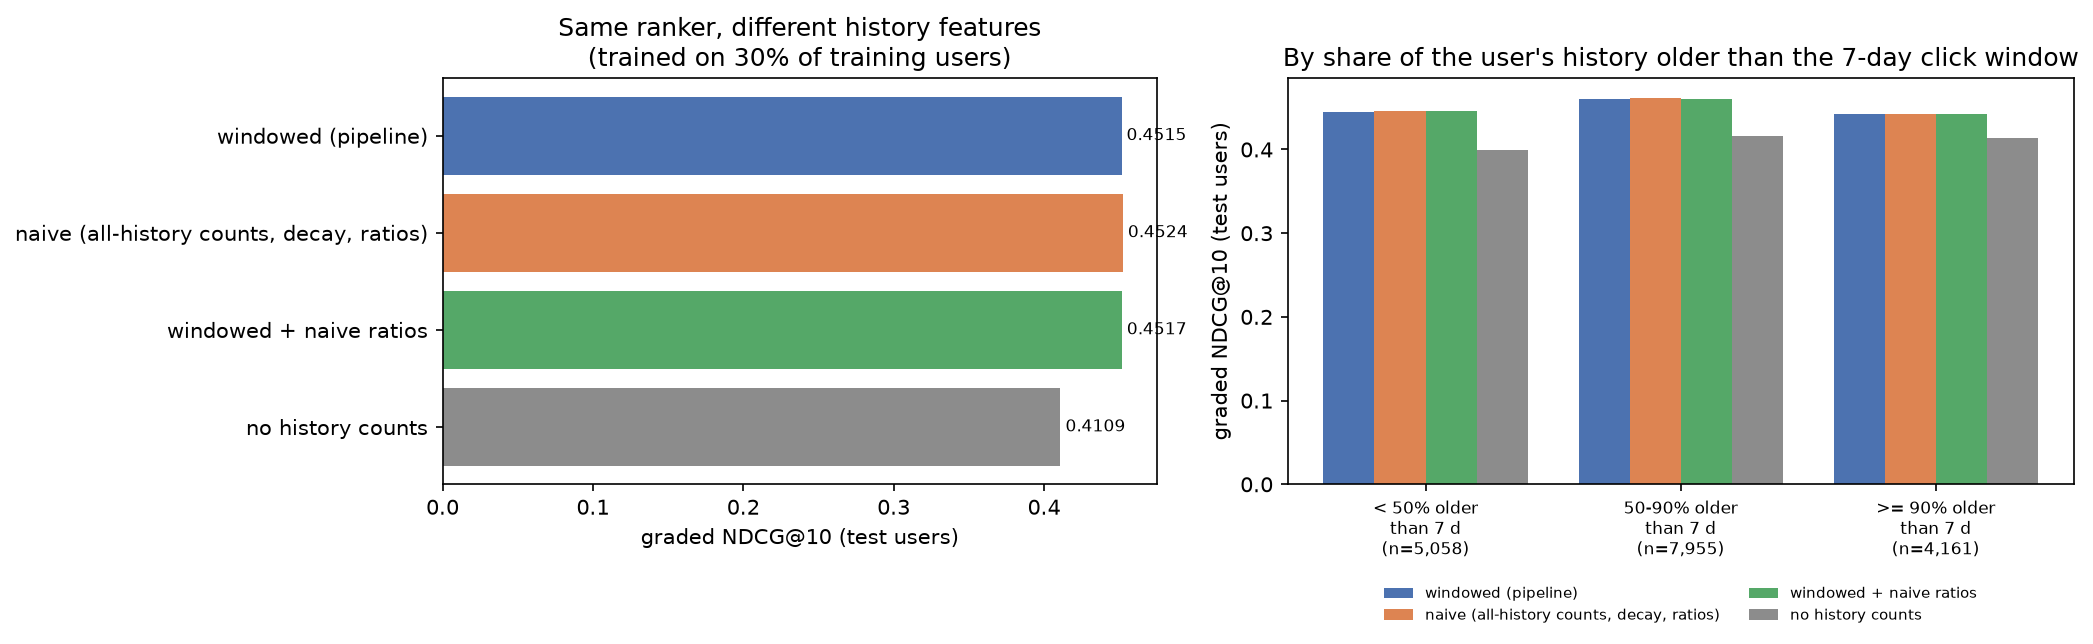

,segment,model,n,mrr,gndcg10
0,50-90% older than 7 d,"naive (all-history counts, decay, ratios)",7955,0.4661,0.4618
1,50-90% older than 7 d,no history counts,7955,0.4156,0.4167
2,50-90% older than 7 d,windowed (pipeline),7955,0.4648,0.4604
3,50-90% older than 7 d,windowed + naive ratios,7955,0.4650,0.4605
4,< 50% of history older than 7 d,"naive (all-history counts, decay, ratios)",5058,0.4597,0.4455
5,< 50% of history older than 7 d,no history counts,5058,0.4071,0.3997
6,< 50% of history older than 7 d,windowed (pipeline),5058,0.4602,0.4450
7,< 50% of history older than 7 d,windowed + naive ratios,5058,0.4598,0.4454
8,>= 90% older than 7 d,"naive (all-history counts, decay, ratios)",4161,0.4450,0.4428
9,>= 90% older than 7 d,no history counts,4161,0.4122,0.4134


In [4]:
run.figure("window_ablation.png")
run.table("window_ablation_segments.csv", highlight=("mrr", "gndcg10"))